# NYC Property Sales: Exploratory Data Analysis

This notebook explores the cleaned NYC Property Sales dataset to better understand the factors associated with property sale price. The analysis focuses on the distribution of sale prices, differences across boroughs, changes over time, and relationships between property characteristics and sale price.

In [3]:
import os

csv_files = [
    f for f in os.listdir(".")
    if f.endswith(".csv")
    and "-checkpoint" not in f
    and f != "BuildingClassification.csv"
]

print("Number of sales CSV files:", len(csv_files))
print(csv_files[:10])

Number of sales CSV files: 87
['2009_StatenIsland.csv', '05_Manhattan.csv', '2017_Bronx.csv', '04_Bronx.csv', '2013_StatenIsland.csv', '2008_Queens.csv', '2009_Manhattan.csv', '2007_StatenIsland.csv', '2014_Manhattan.csv', '2011_Manhattan.csv']


In [4]:
import os

boroughs = ["Bronx", "Brooklyn", "Manhattan", "Queens", "StatenIsland"]

csv_files = [
    f for f in os.listdir(".")
    if f.endswith(".csv")
    and "-checkpoint" not in f
    and any(borough in f for borough in boroughs)
]

csv_files = sorted(csv_files)

print("Number of NYC sales CSV files:", len(csv_files))
print(csv_files[:10])

Number of NYC sales CSV files: 85
['03_Bronx.csv', '03_Brooklyn.csv', '03_Manhattan.csv', '03_Queens.csv', '03_StatenIsland.csv', '04_Bronx.csv', '04_Brooklyn.csv', '04_Manhattan.csv', '04_Queens.csv', '04_StatenIsland.csv']


In [5]:
from collections import Counter

def year_and_borough(path):
    name = os.path.basename(path).replace(".csv", "")
    year, borough = name.split("_", 1)

    year = int(year)

    if year < 100:
        year += 2000

    if borough == "StatenIsland":
        borough = "Staten Island"

    return year, borough


print(Counter(year_and_borough(f)[1] for f in csv_files))
print(Counter(year_and_borough(f)[0] for f in csv_files))

Counter({'Bronx': 17, 'Brooklyn': 17, 'Manhattan': 17, 'Queens': 17, 'Staten Island': 17})
Counter({2003: 5, 2004: 5, 2005: 5, 2006: 5, 2007: 5, 2008: 5, 2009: 5, 2010: 5, 2011: 5, 2012: 5, 2013: 5, 2014: 5, 2015: 5, 2016: 5, 2017: 5, 2018: 5, 2019: 5})


In [6]:
# Standardize old column names
rename_map = {
    "Tax Class As Of Final Roll 18/1": "Tax Class At Present",
    "Building Class As Of Final Roll 18/1": "Building Class At Present"
}

dfs = []

for f in csv_files:
    year, borough = year_and_borough(f)

    temp_df = spark.read.csv(f, header=True)

    for old_name, new_name in rename_map.items():
        if old_name in temp_df.columns:
            temp_df = temp_df.withColumnRenamed(old_name, new_name)

    temp_df = temp_df.withColumn("Year", F.lit(year))
    temp_df = temp_df.withColumn("Borough_Name", F.lit(borough))

    dfs.append(temp_df)

combined_df = dfs[0]

for temp_df in dfs[1:]:
    combined_df = combined_df.unionByName(
        temp_df,
        allowMissingColumns=True
    )

print("Total rows:", combined_df.count())
print("Total columns:", len(combined_df.columns))

combined_df.select(
    "Borough",
    "Borough_Name",
    "Year",
    "Sale Price"
).show(5)

Total rows: 1626742
Total columns: 23
+-------+------------+----+----------+
|Borough|Borough_Name|Year|Sale Price|
+-------+------------+----+----------+
|      2|       Bronx|2003|    130000|
|      2|       Bronx|2003|    204000|
|      2|       Bronx|2003|    235000|
|      2|       Bronx|2003|    125500|
|      2|       Bronx|2003|    215000|
+-------+------------+----+----------+
only showing top 5 rows


In [7]:
from pyspark.sql.types import StringType

# Start with the consolidated dataset
df = combined_df

# Remove fully empty rows from the source CSV files
df = df.filter(F.col("Borough").isNotNull())

# Rename Ease-Ment to make it easier to reference
df = df.withColumnRenamed("Ease-Ment", "EaseMent")

# Find all string columns
string_cols = [
    field.name
    for field in df.schema.fields
    if isinstance(field.dataType, StringType)
]

# Trim whitespace from string columns
for col_name in string_cols:
    df = df.withColumn(
        col_name,
        F.trim(F.col(col_name))
    )

# Replace blank strings with NULL
for col_name in string_cols:
    df = df.withColumn(
        col_name,
        F.when(
            F.col(col_name) == "",
            None
        ).otherwise(F.col(col_name))
    )

# Drop EaseMent
df = df.drop("EaseMent")

print("Rows after removing empty rows:", df.count())
print("Columns after cleaning:", len(df.columns))

[Stage 89:==================================================>   (113 + 4) / 122]

Rows after removing empty rows: 1600162
Columns after cleaning: 22


In [8]:
# Cast numeric and date columns to the correct types

df = (
    df
    .withColumn("Sale Price", F.col("Sale Price").cast("double"))
    .withColumn("Residential Units", F.col("Residential Units").cast("integer"))
    .withColumn("Commercial Units", F.col("Commercial Units").cast("integer"))
    .withColumn("Total Units", F.col("Total Units").cast("integer"))
    .withColumn("Land Square Feet", F.col("Land Square Feet").cast("double"))
    .withColumn("Gross Square Feet", F.col("Gross Square Feet").cast("double"))
    .withColumn("Year Built", F.col("Year Built").cast("integer"))
    .withColumn("Zip Code", F.col("Zip Code").cast("integer"))
    .withColumn("Borough", F.col("Borough").cast("integer"))
    .withColumn("Sale Date", F.to_date(F.col("Sale Date")))
)

df.printSchema()

root
 |-- Borough: integer (nullable = true)
 |-- Neighborhood: string (nullable = true)
 |-- Building Class Category: string (nullable = true)
 |-- Tax Class At Present: string (nullable = true)
 |-- Block: string (nullable = true)
 |-- Lot: string (nullable = true)
 |-- Building Class At Present: string (nullable = true)
 |-- Address: string (nullable = true)
 |-- Apartment Number: string (nullable = true)
 |-- Zip Code: integer (nullable = true)
 |-- Residential Units: integer (nullable = true)
 |-- Commercial Units: integer (nullable = true)
 |-- Total Units: integer (nullable = true)
 |-- Land Square Feet: double (nullable = true)
 |-- Gross Square Feet: double (nullable = true)
 |-- Year Built: integer (nullable = true)
 |-- Tax Class At Time Of Sale: string (nullable = true)
 |-- Building Class At Time Of Sale: string (nullable = true)
 |-- Sale Price: double (nullable = true)
 |-- Sale Date: date (nullable = true)
 |-- Year: integer (nullable = false)
 |-- Borough_Name: string 

In [9]:
# Save cleaned dataset for EDA

output_path = "data/nyc_property_sales_cleaned"

df.write.mode("overwrite").parquet(output_path)

print("Saved cleaned data to:", output_path)

26/10/28 11:08:00 WARN DAGScheduler: Broadcasting large task binary with size 3.0 MiB
                                                                                

Saved cleaned data to: data/nyc_property_sales_cleaned


## 1. Sale Price Distribution

Sale Price is the primary variable of interest for this project. We first examine how many transactions have a positive sale price compared with transactions recorded at $0. Zero-dollar transactions may represent non-market transfers, so positive-price transactions will be examined separately in later analyses.

In [10]:
sale_price_summary = (
    df
    .groupBy(
        F.when(F.col("Sale Price") == 0, "$0")
         .otherwise("> $0")
         .alias("Sale Price Category")
    )
    .count()
)

total_sales = df.count()

sale_price_summary = (
    sale_price_summary
    .withColumn(
        "Percentage",
        F.round((F.col("count") / total_sales) * 100, 2)
    )
    .orderBy(F.desc("count"))
)

sale_price_summary.show()

[Stage 96:=====================================================>(121 + 1) / 122]

+-------------------+-------+----------+
|Sale Price Category|  count|Percentage|
+-------------------+-------+----------+
|               > $0|1116476|     69.77|
|                 $0| 483686|     30.23|
+-------------------+-------+----------+



/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

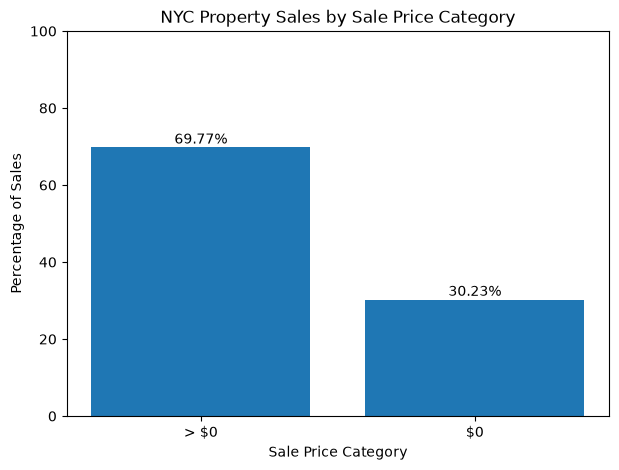

In [11]:
import matplotlib.pyplot as plt

sale_price_pd = sale_price_summary.toPandas()

plt.figure(figsize=(7, 5))

plt.bar(
    sale_price_pd["Sale Price Category"],
    sale_price_pd["Percentage"]
)

plt.title("NYC Property Sales by Sale Price Category")
plt.xlabel("Sale Price Category")
plt.ylabel("Percentage of Sales")
plt.ylim(0, 100)

for i, value in enumerate(sale_price_pd["Percentage"]):
    plt.text(i, value + 1, f"{value}%", ha="center")

plt.show()

Approximately 69.8% of the transactions have a positive sale price, while 30.2% are recorded at 0 dollars. Since 0 dollar transactions may represent non-market transfers rather than typical property sales, later sale-price analyses will focus on transactions with a positive sale price.

### Distribution of Positive Sale Prices

Because zero-dollar transactions may not represent typical market sales, we next examine the distribution of transactions with a positive sale price. NYC property prices contain some very large values, so we also examine percentiles to understand the effect of extreme observations.

In [15]:
positive_sales = df.filter(F.col("Sale Price") > 0)

positive_sales.select("Sale Price").describe().show()

price_percentiles = positive_sales.approxQuantile(
    "Sale Price",
    [0.25, 0.50, 0.75, 0.95, 0.99],
    0.001
)

print("25th percentile:", price_percentiles[0])
print("Median:", price_percentiles[1])
print("75th percentile:", price_percentiles[2])
print("95th percentile:", price_percentiles[3])
print("99th percentile:", price_percentiles[4])

+-------+-------------------+
|summary|         Sale Price|
+-------+-------------------+
|  count|            1116476|
|   mean| 1224806.9871443722|
| stddev|1.391111118028807E7|
|    min|                1.0|
|    max|      4.111111766E9|
+-------+-------------------+



26/10/28 11:14:51 WARN DAGScheduler: Broadcasting large task binary with size 1009.4 KiB
[Stage 117:===================================================> (119 + 3) / 122]

25th percentile: 275000.0
Median: 477000.0
75th percentile: 789000.0
95th percentile: 2800000.0
99th percentile: 10000000.0


/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

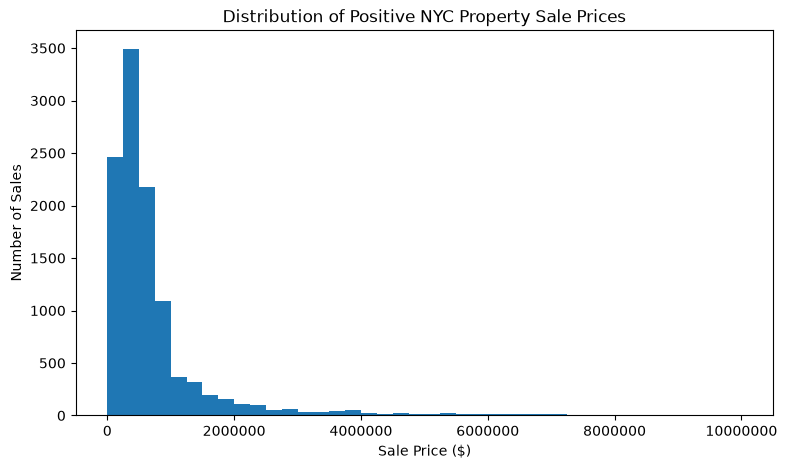

In [16]:
p99 = price_percentiles[4]

price_sample = (
    positive_sales
    .filter(F.col("Sale Price") <= p99)
    .select("Sale Price")
    .sample(False, 0.01, seed=314)
    .toPandas()
)

plt.figure(figsize=(9, 5))

plt.hist(
    price_sample["Sale Price"],
    bins=40
)

plt.title("Distribution of Positive NYC Property Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Sales")

plt.ticklabel_format(style="plain", axis="x")

plt.show()

Positive NYC property sale prices are strongly right-skewed. The median sale price is approximately $470,000, while the mean is approximately $1.22 million, indicating that high-value transactions pull the average upward. The 99th percentile is approximately $10 million, while the maximum transaction exceeds $4 billion. For visualization purposes, the histogram excludes transactions above the 99th percentile so that the distribution of typical sales can be seen more clearly.

## 2. Sale Price by Borough

Location is expected to be an important factor in NYC property values. We compare positive-price transactions across the five boroughs using both the mean and median sale price. Because sale prices contain extreme outliers, median sale price provides a more representative comparison of typical transactions.

In [18]:
borough_summary = (
    positive_sales
    .groupBy("Borough_Name")
    .agg(
        F.count("*").alias("Number of Sales"),
        F.round(F.avg("Sale Price"), 2).alias("Mean Sale Price"),
        F.expr("percentile_approx(`Sale Price`, 0.5)").alias("Median Sale Price")
    )
    .orderBy(F.desc("Median Sale Price"))
)

borough_summary.show(truncate=False)

26/10/28 11:16:17 WARN DAGScheduler: Broadcasting large task binary with size 1023.7 KiB
[Stage 121:===================================================> (118 + 4) / 122]

+-------------+---------------+---------------+-----------------+
|Borough_Name |Number of Sales|Mean Sale Price|Median Sale Price|
+-------------+---------------+---------------+-----------------+
|Manhattan    |310328         |2633360.97     |735000.0         |
|Brooklyn     |281709         |863171.31      |515234.0         |
|Queens       |337184         |598849.73      |409000.0         |
|Staten Island|96475          |462763.38      |394446.0         |
|Bronx        |90780          |666789.97      |359500.0         |
+-------------+---------------+---------------+-----------------+



/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/28 11:17:04 WARN DAGScheduler: Broadcasting large task binary with size 1023.7 KiB
                                                                                

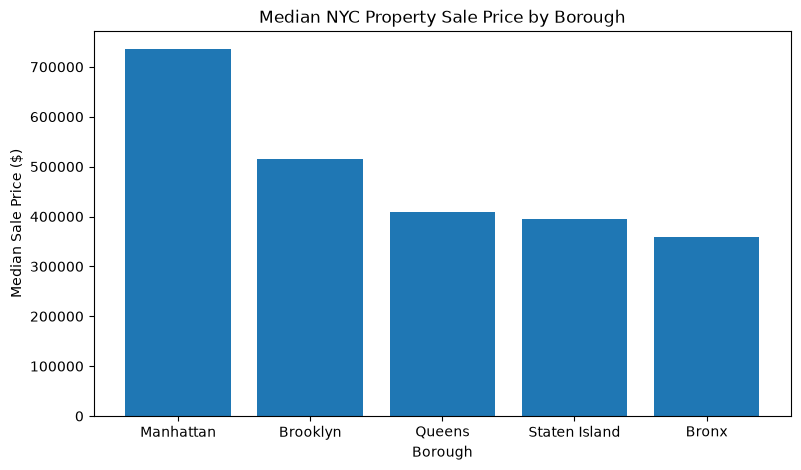

In [19]:
borough_pd = borough_summary.toPandas()

plt.figure(figsize=(9, 5))

plt.bar(
    borough_pd["Borough_Name"],
    borough_pd["Median Sale Price"]
)

plt.title("Median NYC Property Sale Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Median Sale Price ($)")

plt.ticklabel_format(style="plain", axis="y")

plt.show()

Median sale prices vary substantially across NYC boroughs. Manhattan has the highest median sale price at approximately \$735,000, followed by Brooklyn at approximately \$515,000. Queens and Staten Island have similar median prices around \$400,000, while the Bronx has the lowest median at approximately \$360,000. These differences suggest that borough location may be an important predictor of property sale price.

## 3. Sale Price Trends Over Time

The dataset contains property transactions from 2003 through 2019. To examine how NYC property values changed over time, we calculate the median positive sale price for each borough in each year.

In [20]:
year_borough_summary = (
    positive_sales
    .groupBy("Year", "Borough_Name")
    .agg(
        F.expr(
            "percentile_approx(`Sale Price`, 0.5)"
        ).alias("Median Sale Price")
    )
    .orderBy("Year", "Borough_Name")
)

year_borough_summary.show(20, truncate=False)

26/10/28 11:25:46 WARN DAGScheduler: Broadcasting large task binary with size 1034.7 KiB
[Stage 132:=================================================>   (113 + 4) / 122]

+----+-------------+-----------------+
|Year|Borough_Name |Median Sale Price|
+----+-------------+-----------------+
|2003|Bronx        |265000.0         |
|2003|Brooklyn     |325000.0         |
|2003|Manhattan    |436883.0         |
|2003|Queens       |299000.0         |
|2003|Staten Island|299130.0         |
|2004|Bronx        |306940.0         |
|2004|Brooklyn     |381500.0         |
|2004|Manhattan    |524399.0         |
|2004|Queens       |349900.0         |
|2004|Staten Island|342000.0         |
|2005|Bronx        |360500.0         |
|2005|Brooklyn     |465000.0         |
|2005|Manhattan    |590000.0         |
|2005|Queens       |412000.0         |
|2005|Staten Island|390000.0         |
|2006|Bronx        |425000.0         |
|2006|Brooklyn     |535000.0         |
|2006|Manhattan    |631000.0         |
|2006|Queens       |460000.0         |
|2006|Staten Island|421876.0         |
+----+-------------+-----------------+
only showing top 20 rows


/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/28 11:27:00 WARN DAGScheduler: Broadcasting large task binary with size 1034.7 KiB
                                                                                

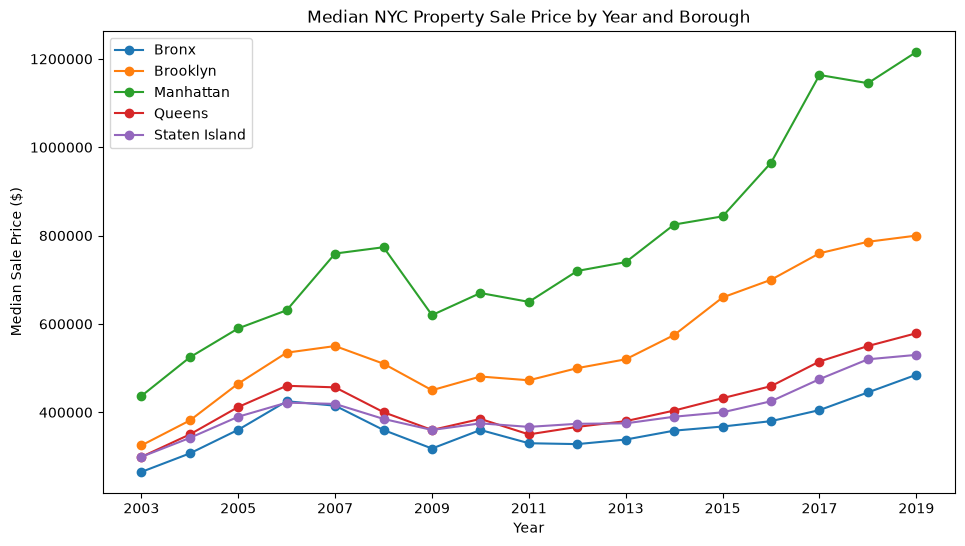

In [21]:
year_borough_pd = year_borough_summary.toPandas()

plt.figure(figsize=(11, 6))

for borough in sorted(year_borough_pd["Borough_Name"].unique()):
    borough_data = year_borough_pd[
        year_borough_pd["Borough_Name"] == borough
    ]

    plt.plot(
        borough_data["Year"],
        borough_data["Median Sale Price"],
        marker="o",
        label=borough
    )

plt.title("Median NYC Property Sale Price by Year and Borough")
plt.xlabel("Year")
plt.ylabel("Median Sale Price ($)")
plt.legend()
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(range(2003, 2020, 2))

plt.show()

Median property sale prices generally increased across all five boroughs from 2003 through 2019, although there was a noticeable decline around 2008–2011. Manhattan consistently had the highest median sale price and experienced the largest increase over the period. Brooklyn also showed strong growth, particularly after 2013. By 2019, median prices were higher than their 2003 levels in every borough, suggesting that both location and year may be important predictors of sale price.

## 4. Property Size and Sale Price

Property size may also help explain differences in sale price. We examine the relationship between gross square feet and positive sale price. To make the relationship easier to visualize, extreme values are excluded from the graph.

In [22]:
size_sales = (
    positive_sales
    .filter(F.col("Gross Square Feet").isNotNull())
    .filter(F.col("Gross Square Feet") > 0)
)

size_percentiles = size_sales.approxQuantile(
    "Gross Square Feet",
    [0.99],
    0.001
)

gross_sqft_p99 = size_percentiles[0]

print("99th percentile Gross Square Feet:", gross_sqft_p99)

correlation = size_sales.stat.corr(
    "Gross Square Feet",
    "Sale Price"
)

print("Correlation between Gross Square Feet and Sale Price:", correlation)

26/10/28 11:29:18 WARN DAGScheduler: Broadcasting large task binary with size 1402.5 KiB
26/10/28 11:29:22 WARN DAGScheduler: Broadcasting large task binary with size 1159.4 KiB
                                                                                

99th percentile Gross Square Feet: 112850.0


26/10/28 11:29:24 WARN DAGScheduler: Broadcasting large task binary with size 1146.0 KiB
[Stage 146:=================================================>   (114 + 4) / 122]

Correlation between Gross Square Feet and Sale Price: 0.47043611235251825


/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/28 11:30:05 WARN DAGScheduler: Broadcasting large task binary with size 1433.8 KiB
                                                                                

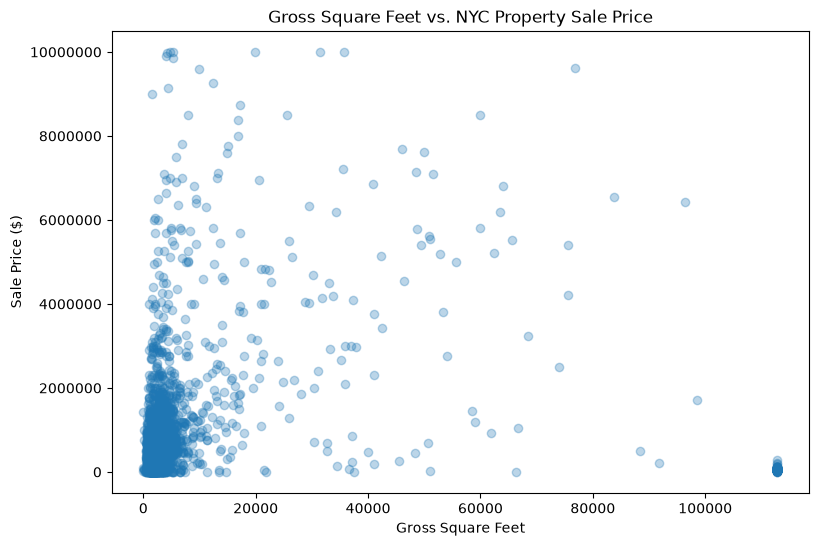

In [23]:
size_price_sample = (
    size_sales
    .filter(F.col("Gross Square Feet") <= gross_sqft_p99)
    .filter(F.col("Sale Price") <= p99)
    .select("Gross Square Feet", "Sale Price")
    .sample(False, 0.01, seed=314)
    .toPandas()
)

plt.figure(figsize=(9, 6))

plt.scatter(
    size_price_sample["Gross Square Feet"],
    size_price_sample["Sale Price"],
    alpha=0.3
)

plt.title("Gross Square Feet vs. NYC Property Sale Price")
plt.xlabel("Gross Square Feet")
plt.ylabel("Sale Price ($)")

plt.ticklabel_format(style="plain", axis="both")

plt.show()

Gross square feet has a moderate positive relationship with sale price, with a correlation of approximately 0.47. Larger properties generally tend to have higher sale prices, but there is substantial variation in price among properties of similar size. This suggests that property size is an important factor, but other characteristics such as location, property type, and year may also help explain sale price.

## 5. Building Type and Sale Price

Property type may also influence sale price. We examine the most frequently sold building class categories and compare their median positive sale prices.

In [24]:
top_building_classes = (
    positive_sales
    .groupBy("Building Class Category")
    .count()
    .orderBy(F.desc("count"))
    .limit(10)
)

top_building_classes.show(truncate=False)

[Stage 150:====================================================>(121 + 1) / 122]

+--------------------------------+------+
|Building Class Category         |count |
+--------------------------------+------+
|10  COOPS - ELEVATOR APARTMENTS |179812|
|13  CONDOS - ELEVATOR APARTMENTS|140551|
|01  ONE FAMILY HOMES            |139418|
|02  TWO FAMILY HOMES            |121162|
|01  ONE FAMILY DWELLINGS        |47316 |
|01 ONE FAMILY DWELLINGS         |40399 |
|02  TWO FAMILY DWELLINGS        |39364 |
|09  COOPS - WALKUP APARTMENTS   |35383 |
|07  RENTALS - WALKUP APARTMENTS |34065 |
|10 COOPS - ELEVATOR APARTMENTS  |33878 |
+--------------------------------+------+



In [25]:
top_class_names = [
    row["Building Class Category"]
    for row in top_building_classes.collect()
]

building_price_summary = (
    positive_sales
    .filter(F.col("Building Class Category").isin(top_class_names))
    .groupBy("Building Class Category")
    .agg(
        F.count("*").alias("Number of Sales"),
        F.expr(
            "percentile_approx(`Sale Price`, 0.5)"
        ).alias("Median Sale Price")
    )
    .orderBy(F.desc("Median Sale Price"))
)

building_price_summary.show(truncate=False)

26/10/28 11:33:43 WARN DAGScheduler: Broadcasting large task binary with size 1543.3 KiB
26/10/28 11:33:47 WARN DAGScheduler: Broadcasting large task binary with size 1059.4 KiB


+--------------------------------+---------------+-----------------+
|Building Class Category         |Number of Sales|Median Sale Price|
+--------------------------------+---------------+-----------------+
|07  RENTALS - WALKUP APARTMENTS |34065          |806190.0         |
|13  CONDOS - ELEVATOR APARTMENTS|140551         |743310.0         |
|02  TWO FAMILY DWELLINGS        |39364          |550000.0         |
|01 ONE FAMILY DWELLINGS         |40399          |550000.0         |
|02  TWO FAMILY HOMES            |121162         |478723.0         |
|10 COOPS - ELEVATOR APARTMENTS  |33878          |460000.0         |
|01  ONE FAMILY DWELLINGS        |47316          |447500.0         |
|01  ONE FAMILY HOMES            |139418         |400000.0         |
|10  COOPS - ELEVATOR APARTMENTS |179812         |320000.0         |
|09  COOPS - WALKUP APARTMENTS   |35383          |235000.0         |
+--------------------------------+---------------+-----------------+



/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/28 11:34:00 WARN DAGScheduler: Broadcasting large task binary with size 1543.3 KiB
26/10/28 11:34:04 WARN DAGScheduler: Broadcasting large task binary with size 1059.5 KiB
26/10/28 11:34:04 WARN DAGScheduler: Broa

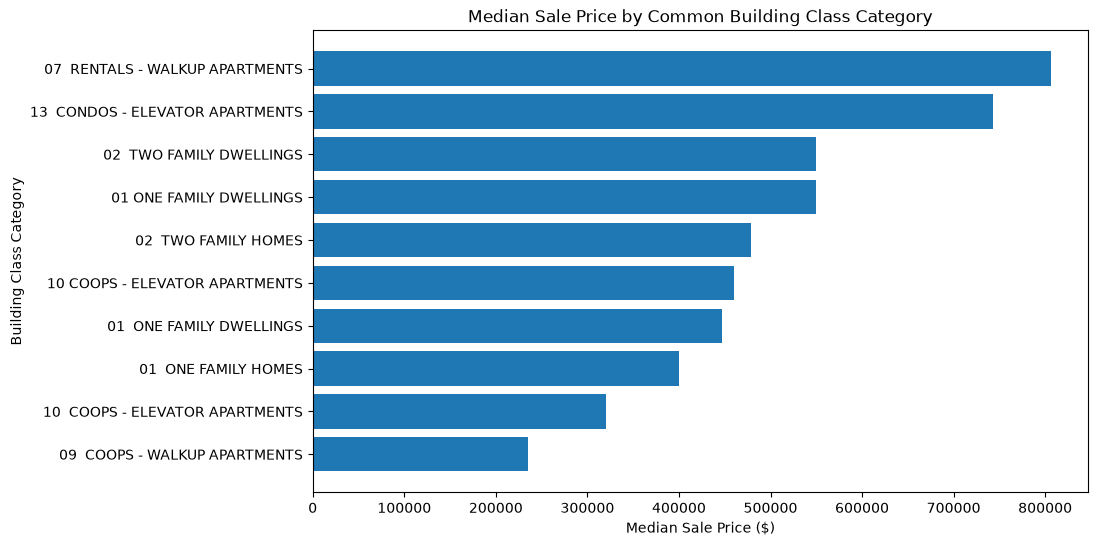

In [26]:
building_price_pd = building_price_summary.toPandas()

plt.figure(figsize=(10, 6))

plt.barh(
    building_price_pd["Building Class Category"],
    building_price_pd["Median Sale Price"]
)

plt.title("Median Sale Price by Common Building Class Category")
plt.xlabel("Median Sale Price ($)")
plt.ylabel("Building Class Category")

plt.ticklabel_format(style="plain", axis="x")

plt.gca().invert_yaxis()

plt.show()

Median sale prices differ substantially across common building class categories. Among the most frequently sold property types, rentals in walk-up apartment buildings and condos in elevator apartment buildings have some of the highest median sale prices, while co-ops in walk-up apartment buildings have lower median prices. These differences suggest that property type may also be an important predictor of sale price. Some building class categories appear under similar historical labels, so the results should be interpreted with that limitation in mind.

## EDA Summary

The exploratory analysis identified several factors that appear related to NYC property sale price. Sale prices are strongly right-skewed, with a relatively small number of very high-value transactions pulling the mean above the median. Approximately 30% of records have a sale price of $0, suggesting that these transactions should be considered separately when modeling market sale prices.

Location appears to be an important factor, as median sale prices differ substantially across boroughs, with Manhattan having the highest median price. Property prices also generally increased between 2003 and 2019, although there were declines during parts of the period. Gross square feet has a moderate positive correlation with sale price, and median prices also vary across building class categories. These findings suggest that borough, year, property size, and building type may all be useful predictors in the modeling stage.